## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

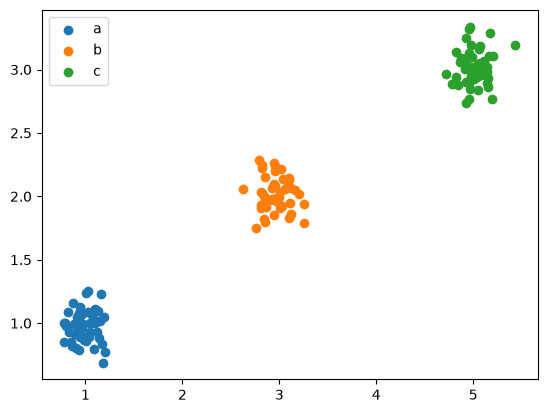

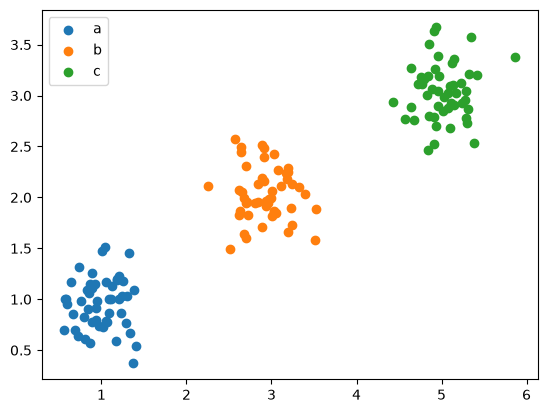

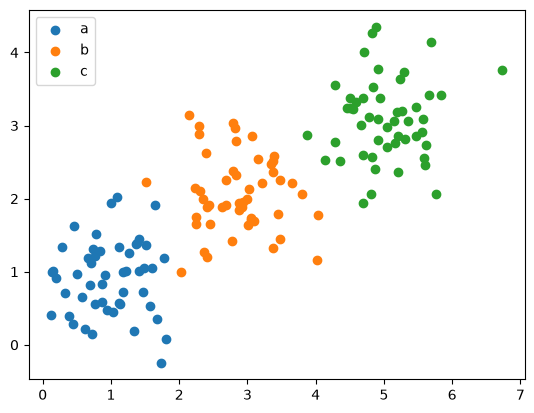

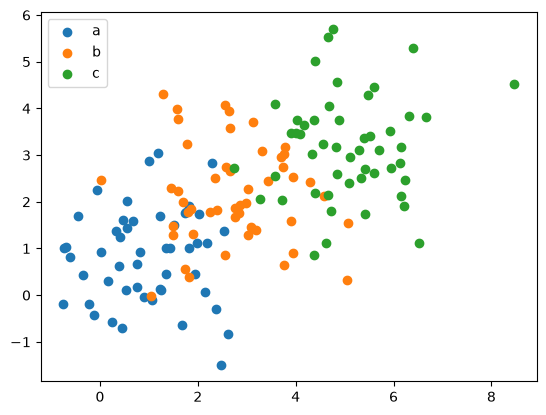

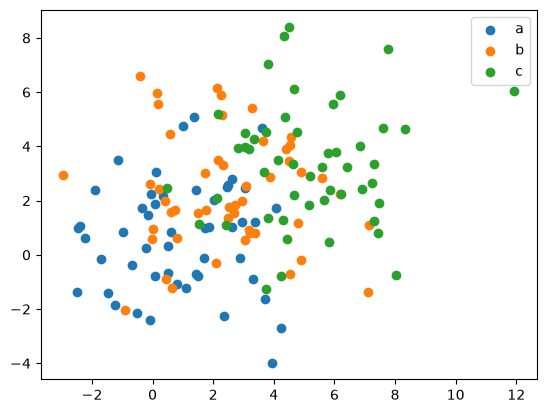

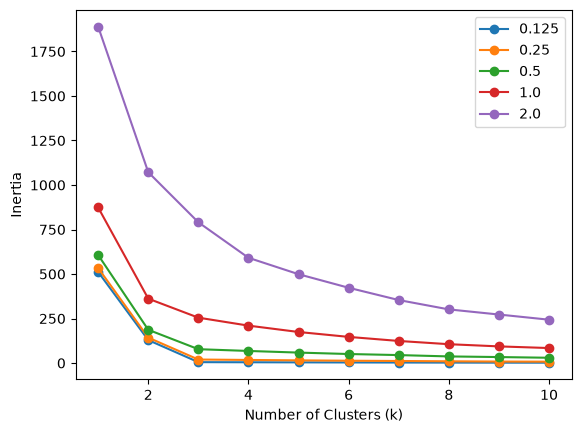

In [ ]:
#Part 1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


import matplotlib.pyplot as plt
#Part 2

dfs = [df0_125, df0_25, df0_5, df1_0, df2_0]
ns = [0.125, 0.25, 0.5, 1.0, 2.0]

for df, n in zip(dfs, ns):
    for g in ['a', 'b', 'c']:
        d = df[df['group'] == g] # filter by group
        plt.scatter(d['x1'], d['x2'], label=g) # plot group

    plt.legend()
    plt.show()



from sklearn.cluster import KMeans
# Part 3
for df, n in zip(dfs, ns):
    scores = []

    for k in range(1, 11):
        m = KMeans(n_clusters=k, random_state=1, n_init=10)
        m.fit(df[['x1', 'x2']]) # fit model
        scores.append(m.inertia_) # store inertia

    plt.plot(range(1, 11), scores, marker='o', label=str(n)) # plot scree curve

plt.legend()
plt.show()

#Part 4
# As noise increases, the clusters overlap more, making it harder to find a clear elbow. 
# At lower noise levels, k=3 is easier to identify because the groups are more distinct. adding more clusters doesn't make any significant impact.


148
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                          0.031352        0.010413  
50%                          0.047402        0.015324  
75%                          0.084681        0.024327  
max                          0.303027        0.098470  


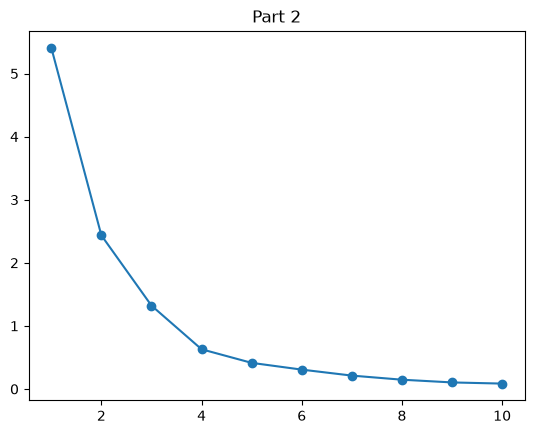

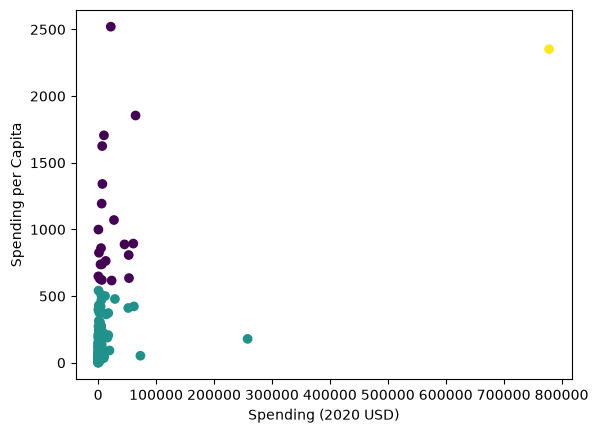

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

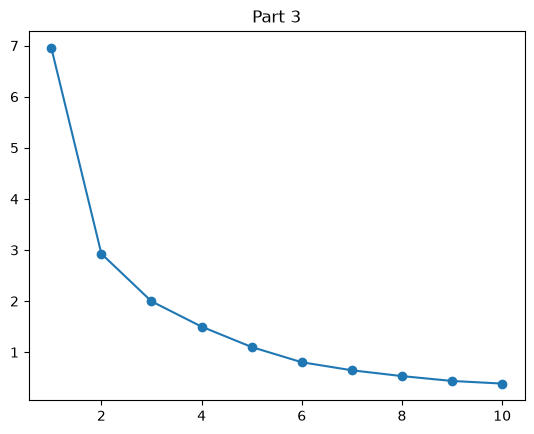

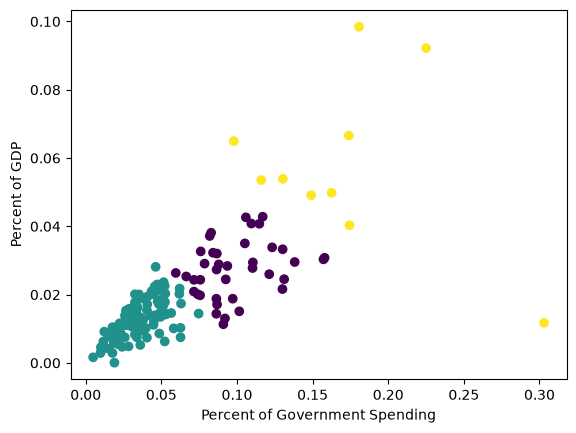

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 99.0  0.035777  0.014549  0.004896   
2                                 10.0  0.171289  0.058725  0.097882   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                     
              std       min       25%   

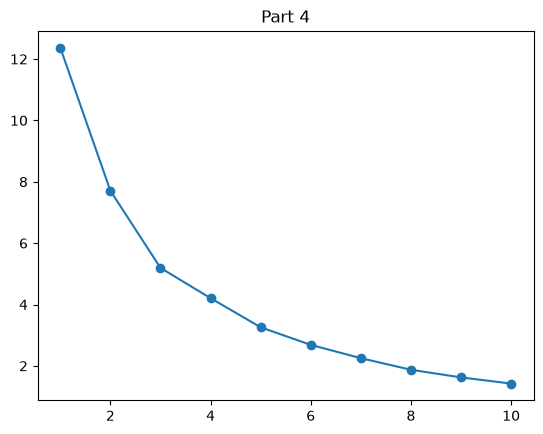

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      31.0    8786.086602   17901.909108   162.373364   
1                     111.0    7086.472777   26479.379918     8.622460   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         467.787851   1404.787234   7739.166193   72937.064048   
1         130.010211    567.650747   3910.107493  257973.429834   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                           

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# part 1

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna() # filter year and missing values

cols = ["Spending (2020 USD)", "Spending per Capita",
        "Percent of Government Spending", "Percent of GDP"]

print(len(df))
print(df[cols].describe())


# part 2

c = cols[:2]
x = MinMaxScaler().fit_transform(df[c]) # normalize data

s = []
for k in range(1, 11):
    m = KMeans(n_clusters=k, random_state=1, n_init=10)
    m.fit(x)
    s.append(m.inertia_) # store inertia

plt.plot(range(1, 11), s, marker='o')
plt.show()

k = 3 # adjust based on elbow
df["cluster"] = KMeans(n_clusters=k, random_state=1, n_init=10).fit_predict(x)

plt.scatter(df[c[0]], df[c[1]], c=df["cluster"]) # color by cluster
plt.xlabel(c[0])
plt.ylabel(c[1])
plt.show()

print(df.groupby("cluster")[c].describe())
print(df[df["Country"] == "United States"][["Country", "cluster"]])


# part 3

c = cols[2:]
x = MinMaxScaler().fit_transform(df[c])

s = []
for k in range(1, 11):
    m = KMeans(n_clusters=k, random_state=1, n_init=10)
    m.fit(x)
    s.append(m.inertia_)

plt.plot(range(1, 11), s, marker='o')
plt.show()

k = 3 # adjust based on elbow
df["cluster"] = KMeans(n_clusters=k, random_state=1, n_init=10).fit_predict(x)

plt.scatter(df[c[0]], df[c[1]], c=df["cluster"])
plt.xlabel(c[0])
plt.ylabel(c[1])
plt.show()

print(df.groupby("cluster")[c].describe())


# part 4

c = cols
x = MinMaxScaler().fit_transform(df[c])

s = []
for k in range(1, 11):
    m = KMeans(n_clusters=k, random_state=1, n_init=10)
    m.fit(x)
    s.append(m.inertia_)

plt.plot(range(1, 11), s, marker='o')
plt.show()

k = 3 # adjust based on elbow
df["cluster"] = KMeans(n_clusters=k, random_state=1, n_init=10).fit_predict(x)

print(df.groupby("cluster")[c].describe())

#Explanations:

#Part 1: After removing missing values and filtering for 2020, 148 countries remained. No further cleaning was needed.
#Part 2: The elbow is around k=3 to k=4. Most countries are in one cluster, 21 have higher spending , and one outlier has every high total spending.
#Part 3: The elbow is less clear, but k=3 works. Countries are grouped by low, medium, and high military spending percentages rather than total spending.
#Part 4: Using all four variables changes the clusters. Most countries remain grouped together, while smaller groups have higher spending percentages
#Part 5: K-means helped show different miliktary spending patterns, but outliers and overlapping clusters made some results harder to interpret.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [20]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]